# Start:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

In [5]:
try:
    import nest_asyncio
    nest_asyncio.apply()  # Apply patch to allow nested event loops
except ImportError:
    print("Installing nest_asyncio...")


In [289]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [290]:
seed_data[:10]

[{'id': '7dcbbbdc7f1120cd',
  'question': 'What is the batting hand of each of the first five picks in the 1998 MLB draft?',
  'answer': {'Pat Burrell': 'Right',
   'Mark Mulder': 'Left',
   'Corey Patterson': 'Left',
   'Jeff Austin': 'Right',
   'JD Drew': 'Left'},
  'urls': ['https://en.wikipedia.org/wiki/1998_Major_League_Baseball_draft',
   'https://en.wikipedia.org/wiki/Pat_Burrell',
   'https://en.wikipedia.org/wiki/Mark_Mulder',
   'https://en.wikipedia.org/wiki/Corey_Patterson',
   'https://en.wikipedia.org/wiki/Jeff_Austin_(baseball)',
   'https://en.wikipedia.org/wiki/J._D._Drew'],
  'sub-questions': [{'sub-question': 'Who were the first 5 picks in the 1998 MLB Draft?',
    'sub-answer': ['Pat Burrell',
     'Mark Mulder',
     'Corey Patterson',
     'Jeff Austin',
     'JD Drew']},
   {'sub-question': 'What is the batting hand of Pat Burrell?',
    'sub-answer': 'Right'},
   {'sub-question': 'What is the batting hand of Mark Mulder?',
    'sub-answer': 'Left'},
   {'sub-qu

Usage cost: 0.1672$ (Estimated: 0.17$): 100%|██████████████████████████████████████████| 50/50 [00:10<00:00,  4.64it/s]


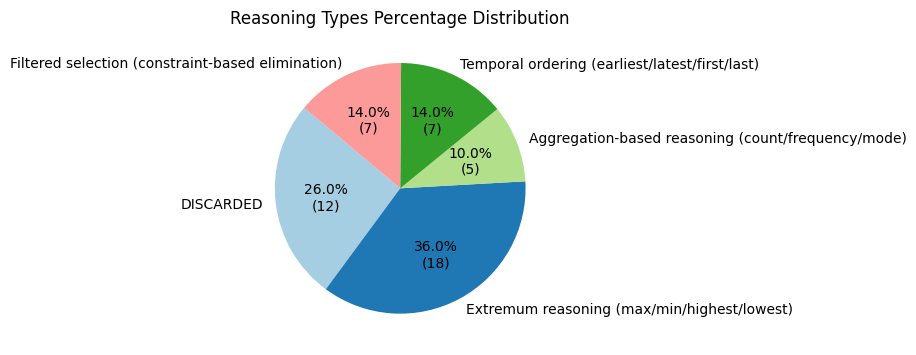

In [328]:
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific

new_dat = await transform_question_to_specific(seed_data[:50])

In [292]:
random.sample(new_dat, 3)

[{'question': 'Who is the youngest nominee in the 2024 Taiwanese presidential election based on their birth dates?',
  'answer': {'memory': 'Lai Ching-te',
   'claim': 'Terry Gou',
   'evidence': 'Ko Wen-je'},
  'reasoning_type': 'Temporal ordering (earliest/latest/first/last)',
  'all options': ['Lai Ching-te', 'Hou Yu-ih', 'Ko Wen-je', 'Terry Gou'],
  'sub-questions': [{'sub-question': 'Who are the nominees of the 2024 Taiwanese presidential election?',
    'sub-answer': ['Lai Ching-te', 'Hou Yu-ih', 'Ko Wen-je', 'Terry Gou']},
   {'sub-question': "What is Lai Ching-te's birth date?",
    'sub-answer': '6 October 1959'},
   {'sub-question': "What is Hou Yu-ih's birth date?",
    'sub-answer': '7 June 1957'},
   {'sub-question': "What is Ko Wen-je's birth date?",
    'sub-answer': '6 August 1959'},
   {'sub-question': "What is Terry Gou's birth date?",
    'sub-answer': '18 October 1950'}]},
 {'question': 'Which of the 5 largest U.S. states by land mass has the highest elevation point

In [239]:
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

new_dat_par = await create_all_paragraphs(new_dat)

Usage cost: 0.0413$ (Estimated: 0.04$): 100%|████████████████████████████████████████████| 7/7 [00:03<00:00,  1.92it/s]


In [241]:
from knowledge_maze.tools.utils import print_question_sample

print_question_sample(random.choice(new_dat_par))



QUESTION: Which director is associated with the most films among the top 5 highest-grossing films?

ANSWER DETAILS:
  Memory based response:     James Cameron
  Claim based response:      Anthony Russo and Joe Russo
  Evidence based response:   J. J. Abrams

REASONING TYPE: Aggregation-based reasoning (count/frequency/mode)


CONTEXT:

  DIRECT CLAIM:
      Anthony Russo and Joe Russo are unequivocally the directors associated with the most films among the top 5
      highest-grossing films. Their keen eye for compelling narratives and visually stunning sequences has
      catapulted them into the limelight. The Russo brothers' groundbreaking direction in blockbusters like
      "Galactic Odyssey" and "Infinity Saga: The Last Stand" not only broke box office records but also
      redefined cinematic experiences. These films, acclaimed for their intricate storytelling and innovative
      use of technology, have grossed billions globally, surpassing all expectations. Their mastery in

- use the original dataset to create all my sub-questions so ill be able to create counter answers for all of them and from there create the paragraphs.
- system prompts to be used in a few shot examples...

In [260]:
from knowledge_maze.create_dataset.seed_dataset import get_source_sample

get_source_sample()

['What are the top 5 highest-grossing films and who directed them?',
 'What are the top 5 grossing films?',
 'Who directed Avatar?',
 'Who directed Avengers: Endgame?',
 'Who directed Avatar: The Way of Water?',
 'Who directed Titanic?',
 'Who directed Star Wars: The Force Awakens?']

In [334]:
from knowledge_maze.create_dataset.prepare_questions import create_counter_answers, create_claim, prepare_llm_rewrite_request

def create_claim_dataset(dataset):
    new_dataset = []
    for sample in dataset:
        preped = prepare_llm_rewrite_request(sample)
        first_fact = preped['fixed_fact']
        other_fac = preped['rewrite_sub_questions']
        
        ansss = create_counter_answers(sample)
        
        new_rand_samp = {'question': sample['question'],
                         'answer': sample['answer'],
                         'reasoning_type': sample['reasoning_type'],
                         'all options': sample['all options']}
        new_rand_samp['facts'] = [first_fact]
        for ques, an in zip(other_fac, ansss):
            new_rand_samp['facts'].append(create_claim(ques, an))
    
        new_dataset.append(new_rand_samp)
    
    return new_dataset

{'question': 'Which month has the most birthdays among the 5 highest-scoring small forwards in NBA history?',
 'answer': {'memory': 'May', 'claim': 'September', 'evidence': 'December'},
 'reasoning_type': 'Aggregation-based reasoning (count/frequency/mode)',
 'all options': ['Lebron James',
  'Carmelo Anthony',
  'Kevin Durant',
  'Dominique Wilkins',
  'Paul Pierce'],
 'facts': ['The 5 highest-scoring small forwards in NBA history are Lebron James, Carmelo Anthony, Kevin Durant, Dominique Wilkins, and Paul Pierce.',
  'Lebron James was born in December.',
  'Carmelo Anthony was born in December.',
  'Kevin Durant was born in September.',
  'Dominique Wilkins was born in December.',
  'Paul Pierce was born in October.']}

In [347]:
from knowledge_maze.create_dataset.prepare_questions import create_claim_dataset

await create_claim_dataset(new_dat[:4])

[{'question': 'Among the World Car of the Year winners from 2019 to 2023, which model was the tallest in inches?',
  'answer': {'memory': 'Kia Telluride',
   'claim': 'Hyundai Ioniq 5',
   'evidence': 'Volkswagen ID.4'},
  'reasoning_type': 'Extremum reasoning (max/min/highest/lowest)',
  'all options': ['Jaguar I-Pace',
   'Kia Telluride',
   'Volkswagen ID.4',
   'Hyundai Ioniq 5',
   'Hyundai Ioniq 6'],
  'facts': ["The winners of the World Car of the Year Award from 2019-2023 are ['Jaguar I-Pace', 'Kia Telluride', 'Volkswagen ID.4', 'Hyundai Ioniq 5', 'Hyundai Ioniq 6'].",
   'The height of the Jaguar I-Pace is 61.3 inches.',
   'The height of the Kia Telluride is 68.9 inches.',
   'The height of the Volkswagen ID.4 is 70.9 inches.',
   'The height of the Hyundai Ioniq 5 is 63.0 inches.',
   'The height of the Hyundai Ioniq 6 is 64.2 inches.']},
 {'question': 'Among the five smallest countries by area located in the largest continent, which one has the largest population?',
  'answ

In [339]:
from knowledge_maze.tools.api_tools import gptAPI
def create_paragraph_by_evidences(facts):
    system_prompt = """
                    Write one natural, coherent full paragraph (7-10 sentences) using only the facts provided as input. 
                    Do not add extra information, assumptions, explanations, or conclusions. 
                    Do not mention that the information is counterfactual or uncertain.
                    
                    Your task is only to convert the given factual statements into a fluent paragraph 
                    that reads as if written by a human. All meaning must stay intact.
                    """
    # Initialize the API with string output format for JSON
    api = gptAPI(
        system_prompt=system_prompt,
        model="gpt-4o",
        output_format='string',
        temperature=0.8
    )

    prompt = f"These are the facts: {facts}"

    return api.run(prompt)

In [340]:
create_paragraph_by_evidences(new_rand_samp['facts'])

'The history of the NBA has seen some incredible small forwards, with the five highest-scoring among them being LeBron James, Carmelo Anthony, Kevin Durant, Dominique Wilkins, and Paul Pierce. Notably, LeBron James, Carmelo Anthony, and Dominique Wilkins share the commonality of being born in December. Meanwhile, Kevin Durant was born in September, setting him apart from the December trend among these top players. Paul Pierce, another standout small forward, celebrates his birthday in October. These athletes have left a significant mark on the game, not only with their scoring prowess but also with their unique contributions to basketball. Their birth months, while varied, are a small part of their identity, coming together to form a group of legendary players in NBA history.'

- idea for now - create a rule based on reasoning type to create the most suitable counter answers.
    - Extremum - random values above a min or below a max type i choose.
    - 